# Vision — Klasifikasi CLIP Zero-shot (tanpa latih) + linear probe
**Kapan dipakai:** label latih sangat sedikit atau TIDAK ADA, dan kelasnya bisa ditulis dengan
kata bahasa Inggris (cat, dog, car, Persian cat, beagle). Punya cukup label (puluhan per
kelas)? Bagian "linear probe" di bawah atau `klasifikasi_embedding` biasanya lebih bagus.

**Bentuk data yang didukung** (pilih satu sel di bagian Baca data):
1. CSV `id,label` + gambar dalam satu folder (aktif)
2. folder per kelas: `train/<kelas>/*.jpg`
3. label tertulis di nama file: `Abyssinian_12.jpg` → `Abyssinian`
Tidak ada train sama sekali? Cukup isi `CLASS_TEXT` manual dan baca test saja.

**Langkah:** nama kelas → kalimat bahasa Inggris (beberapa template, dirata-rata) → CLIP
mengubah gambar dan kalimat jadi vektor → tiap gambar diberi kelas yang kalimatnya paling mirip.

**Data demo:** `pets` = foto 10 ras kucing/anjing (Oxford-IIIT Pet). Nama kelas berupa kode
(`staffordshire_bull_terrier`) sehingga perlu diterjemahkan ke kalimat.
Bobot: `pretrained/clip_b32`.

In [1]:
import glob
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import train_test_split
from torch.nn import functional
from transformers import CLIPModel, CLIPProcessor

Z:\GEMASTIK\Vignate-GEMASTIK\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Konfigurasi
`CLASS_TEXT`: nama kelas soal → teks bahasa Inggris untuk CLIP. Kelas yang tidak diisi memakai
namanya sendiri dengan `_` diganti spasi. Label bahasa Indonesia WAJIB diterjemahkan
(CLIP dilatih dengan teks Inggris): `{"kucing": "cat", "mobil": "car"}`.

In [2]:
DATA_FOLDER = "../../data_latihan/vision/pets"    # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/train.csv"
TEST_CSV = f"{DATA_FOLDER}/test.csv"              # tidak ada? pakai sample_submission.csv
TRAIN_IMAGE_FOLDER = f"{DATA_FOLDER}/train"
TEST_IMAGE_FOLDER = f"{DATA_FOLDER}/test"
TEST_KEY_CSV = f"{DATA_FOLDER}/test_labels.csv"   # hanya ada di data latihan
CLIP_FOLDER = "../../pretrained/clip_b32"
OUTPUT_FOLDER = "../../outputs/vision/klasifikasi_clip"   # di luar repo
os.makedirs(OUTPUT_FOLDER, exist_ok=True)

ID_COL = "id"           # kolom nama file gambar (juga kolom id di submission)
TARGET = "label"        # kolom kelas
IMAGE_EXTENSION = ""    # isi ".jpg" bila kolom id TIDAK memuat ekstensi (misalnya "img_01")
CLASS_TEXT = {"Bengal": "Bengal cat", "Persian": "Persian cat", "Siamese": "Siamese cat",
              "Egyptian_Mau": "Egyptian Mau cat", "pug": "pug dog", "beagle": "beagle dog"}
TEMPLATES = ["a photo of a {}, a type of pet.", "a photo of a {}.", "a close-up photo of a {}.",
             "a blurry photo of a {}."]   # beberapa kalimat dirata-rata = lebih stabil
BATCH_SIZE = 64
VAL_FRACTION = 0.2
SEED = 42
DEVICE = "cpu"
if torch.cuda.is_available():
    DEVICE = "cuda"

## Baca data — bentuk 1: CSV `id,label` + folder gambar (aktif)
Kolom `path` = lokasi file gambar. `astype(str)` supaya id berupa angka (`101`) juga bisa.

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
train["path"] = TRAIN_IMAGE_FOLDER + "/" + train[ID_COL].astype(str) + IMAGE_EXTENSION
test["path"] = TEST_IMAGE_FOLDER + "/" + test[ID_COL].astype(str) + IMAGE_EXTENSION
print("train:", train.shape, "| test:", test.shape)
print("contoh path:", train["path"].iloc[0])
train.head()

train: (805, 4) | test: (269, 2)
contoh path: ../../data_latihan/vision/pets/train/Siamese_24.jpg


,id,label,spesies,path
0,Siamese_24.jpg,Siamese,kucing,../../data_latihan/vision/pets/train/Siamese_2...
1,beagle_198.jpg,beagle,anjing,../../data_latihan/vision/pets/train/beagle_19...
2,Abyssinian_204.jpg,Abyssinian,kucing,../../data_latihan/vision/pets/train/Abyssinia...
3,beagle_153.jpg,beagle,anjing,../../data_latihan/vision/pets/train/beagle_15...
4,Abyssinian_72.jpg,Abyssinian,kucing,../../data_latihan/vision/pets/train/Abyssinia...


## (Alternatif) bentuk 2: folder per kelas `train/<kelas>/*.jpg`
Nama subfolder = label. Test biasanya satu folder tanpa label. Hapus `#` untuk memakai.

In [4]:
# rows = []
# for class_name in sorted(os.listdir(TRAIN_IMAGE_FOLDER)):
#     for path in sorted(glob.glob(f"{TRAIN_IMAGE_FOLDER}/{class_name}/*")):
#         rows.append([os.path.basename(path), class_name, path])
# train = pd.DataFrame(rows, columns=[ID_COL, TARGET, "path"])
# test = pd.DataFrame()
# test["path"] = sorted(glob.glob(f"{TEST_IMAGE_FOLDER}/*"))
# test[ID_COL] = test["path"].apply(os.path.basename)   # cocokkan dengan format sample_submission
# print("train:", train.shape, "| test:", test.shape)

## (Alternatif) bentuk 3: label di nama file `Abyssinian_12.jpg`
`rsplit("_", n=1)` memotong di garis bawah TERAKHIR: `shiba_inu_7` → `shiba_inu`.

In [5]:
# train = pd.DataFrame()
# train["path"] = sorted(glob.glob(f"{TRAIN_IMAGE_FOLDER}/*"))
# train[ID_COL] = train["path"].apply(os.path.basename)
# train[TARGET] = train[ID_COL].str.rsplit("_", n=1).str[0]
# print(train[TARGET].value_counts())

## EDA: label
Zero-shot tidak memakai label untuk belajar; label hanya untuk MENGUKUR. Kelas tidak seimbang
tetap berarti metrik yang dipakai harus F1 macro.

In [6]:
counts = train[TARGET].value_counts()
print(counts)
print("jumlah kelas:", len(counts), "| rasio terbanyak/tersedikit:",
      round(counts.max() / counts.min(), 1))
print("id ganda:", train[ID_COL].duplicated().sum(), "| label kosong:", train[TARGET].isna().sum())

label
Abyssinian                    149
beagle                        135
pug                           120
Persian                       105
Siamese                        82
shiba_inu                      67
Bengal                         53
yorkshire_terrier              41
Egyptian_Mau                   30
staffordshire_bull_terrier     23
Name: count, dtype: int64
jumlah kelas: 10 | rasio terbanyak/tersedikit: 6.5
id ganda: 0 | label kosong: 0


## EDA: file gambar (ada? format asli? ukuran?)
Ekstensi belum tentu benar: `format` dibaca dari isi file. `mode` RGB = berwarna, L = abu-abu,
RGBA = ada transparansi, P = palet (GIF). Semuanya nanti diubah ke RGB.

In [7]:
def image_info(paths):
    rows = []
    for path in paths:
        if not os.path.exists(path):
            rows.append([path, "TIDAK ADA", "", 0, 0])
            continue
        image = Image.open(path)
        rows.append([path, image.format, image.mode, image.width, image.height])
    return pd.DataFrame(rows, columns=["path", "format", "mode", "width", "height"])


train_info = image_info(train["path"])
test_info = image_info(test["path"])
print("format train:", train_info["format"].value_counts().to_dict())
print("format test :", test_info["format"].value_counts().to_dict())
print("mode train:", train_info["mode"].value_counts().to_dict())
print("mode test :", test_info["mode"].value_counts().to_dict())
train_info[(train_info["format"] != "JPEG") | (train_info["mode"] != "RGB")]

format train: {'JPEG': 800, 'GIF': 3, 'PNG': 2}
format test : {'JPEG': 268, 'GIF': 1}
mode train: {'RGB': 800, 'P': 3, 'RGBA': 2}
mode test : {'RGB': 267, 'P': 1, 'L': 1}


,path,format,mode,width,height
68,../../data_latihan/vision/pets/train/Egyptian_...,GIF,P,300,214
100,../../data_latihan/vision/pets/train/Egyptian_...,PNG,RGBA,183,275
122,../../data_latihan/vision/pets/train/Egyptian_...,GIF,P,183,275
126,../../data_latihan/vision/pets/train/Egyptian_...,GIF,P,246,175
572,../../data_latihan/vision/pets/train/Abyssinia...,PNG,RGBA,200,150


## Kelas → kalimat untuk CLIP
Periksa daftar ini dengan teliti: teks yang jelek = skor jelek. Teks yang lebih spesifik
("Persian cat" bukan "Persian") membantu, karena "Persian" juga bisa berarti karpet/bahasa.

In [8]:
classes = sorted(train[TARGET].unique())
# classes = ["kucing", "anjing"]        # tanpa train: tulis daftar kelas manual
class_texts = []
for class_name in classes:
    text = CLASS_TEXT.get(class_name, str(class_name).replace("_", " "))
    class_texts.append(text)
    print(f"{class_name:30} → {text}")

Abyssinian                     → Abyssinian
Bengal                         → Bengal cat
Egyptian_Mau                   → Egyptian Mau cat
Persian                        → Persian cat
Siamese                        → Siamese cat
beagle                         → beagle dog
pug                            → pug dog
shiba_inu                      → shiba inu
staffordshire_bull_terrier     → staffordshire bull terrier
yorkshire_terrier              → yorkshire terrier


## Model CLIP + vektor teks tiap kelas (rata-rata semua template)

In [9]:
clip = CLIPModel.from_pretrained(CLIP_FOLDER, local_files_only=True)
processor = CLIPProcessor.from_pretrained(CLIP_FOLDER, local_files_only=True)
clip = clip.to(DEVICE)
clip.eval()

text_vectors = []
for text in class_texts:
    prompts = []
    for template in TEMPLATES:
        prompts.append(template.format(text))
    encoded = processor(text=prompts, return_tensors="pt", padding=True).to(DEVICE)
    with torch.no_grad():
        vectors = clip.get_text_features(**encoded).pooler_output
    vectors = functional.normalize(vectors, dim=-1).mean(0)
    text_vectors.append(functional.normalize(vectors, dim=0).cpu())
text_vectors = torch.stack(text_vectors).numpy()
print("vektor teks:", text_vectors.shape, "| contoh prompt:", TEMPLATES[0].format(class_texts[0]))

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 13717.13it/s]

vektor teks: (10, 512) | contoh prompt: a photo of a Abyssinian, a type of pet.


## Vektor gambar
`processor` sudah mengecilkan & memotong tengah gambar ke 224x224; cukup `convert("RGB")`.

In [10]:
def image_vectors(paths):
    batches = []
    paths = list(paths)
    for start in range(0, len(paths), BATCH_SIZE):
        images = []
        for path in paths[start:start + BATCH_SIZE]:
            images.append(Image.open(path).convert("RGB"))
        encoded = processor(images=images, return_tensors="pt").to(DEVICE)
        with torch.no_grad():
            batches.append(clip.get_image_features(**encoded).pooler_output.cpu())
    return functional.normalize(torch.cat(batches), dim=-1).numpy()


X_all = image_vectors(train["path"])
X_test = image_vectors(test["path"])
print("vektor gambar train:", X_all.shape, "| test:", X_test.shape)

vektor gambar train: (805, 512) | test: (269, 512)


## Zero-shot: evaluasi di SEMUA train (tidak ada yang dilatih, jadi semua bisa dipakai menguji)
Kemiripan = perkalian vektor gambar dan vektor teks; kelas dengan kemiripan tertinggi menang.

F1 macro zero-shot: 0.9346
                            precision    recall  f1-score   support

                Abyssinian       0.99      0.91      0.95       149
                    Bengal       0.87      0.77      0.82        53
              Egyptian_Mau       0.57      0.80      0.67        30
                   Persian       1.00      1.00      1.00       105
                   Siamese       0.93      1.00      0.96        82
                    beagle       0.99      0.98      0.99       135
                       pug       0.99      1.00      1.00       120
                 shiba_inu       0.96      0.97      0.96        67
staffordshire_bull_terrier       1.00      1.00      1.00        23
         yorkshire_terrier       1.00      1.00      1.00        41

                  accuracy                           0.96       805
                 macro avg       0.93      0.94      0.93       805
              weighted avg       0.96      0.96      0.96       805



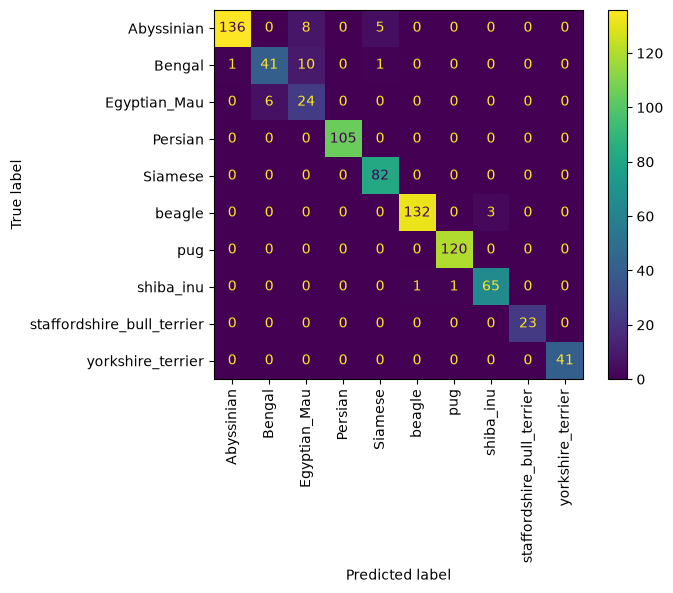

In [11]:
y_all = train[TARGET].to_numpy()
similarity = X_all @ text_vectors.T
zero_shot = np.array(classes)[similarity.argmax(axis=1)]
print("F1 macro zero-shot:", round(f1_score(y_all, zero_shot, average="macro"), 4))
print(classification_report(y_all, zero_shot, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_all, zero_shot, xticks_rotation=90)
plt.show()

## Linear probe: punya label? latih LogisticRegression di vektor gambar CLIP
Biasanya jauh lebih bagus dari zero-shot bila tiap kelas punya puluhan gambar.

In [12]:
train_rows, val_rows = train_test_split(np.arange(len(y_all)), test_size=VAL_FRACTION,
                                        stratify=y_all, random_state=SEED)
probe = LogisticRegression(C=10, max_iter=3000, class_weight="balanced")
probe.fit(X_all[train_rows], y_all[train_rows])
probe_val = probe.predict(X_all[val_rows])
zero_shot_val = zero_shot[val_rows]
print("validasi yang sama | zero-shot F1:",
      round(f1_score(y_all[val_rows], zero_shot_val, average="macro"), 4),
      "| linear probe F1:", round(f1_score(y_all[val_rows], probe_val, average="macro"), 4))

validasi yang sama | zero-shot F1: 0.946 | linear probe F1: 0.9755


## Submission
Pilih SATU: zero-shot (aktif, tanpa label) atau linear probe (dilatih ulang di semua train).

In [13]:
predictions = np.array(classes)[(X_test @ text_vectors.T).argmax(axis=1)]
# probe.fit(X_all, y_all)
# predictions = probe.predict(X_test)

submission = pd.DataFrame()
submission[ID_COL] = test[ID_COL]
submission[TARGET] = predictions
submission.to_csv(f"{OUTPUT_FOLDER}/submission.csv", index=False)
print(submission.shape)
print(submission[TARGET].value_counts())
submission.head()

(269, 2)
label
Abyssinian                    50
beagle                        45
pug                           40
Persian                       35
Siamese                       30
shiba_inu                     23
Egyptian_Mau                  14
yorkshire_terrier             14
Bengal                        11
staffordshire_bull_terrier     7
Name: count, dtype: int64


,id,label
0,test_0001.jpg,pug
1,test_0002.jpg,Egyptian_Mau
2,test_0003.jpg,shiba_inu
3,test_0004.jpg,Abyssinian
4,test_0005.jpg,Siamese


## Cek dengan kunci jawaban latihan (HAPUS saat lomba)

In [14]:
test_key = pd.read_csv(TEST_KEY_CSV)
print("urutan id sama:", (test_key["id"] == submission[ID_COL]).all())
print("F1 macro test:", round(f1_score(test_key["label"], predictions, average="macro"), 4))

urutan id sama: True
F1 macro test: 0.9505


## Masalah umum
- **Satu kelas hampir selalu menang:** teksnya terlalu umum ("animal") atau ambigu. Buat teks
  tiap kelas lebih spesifik di `CLASS_TEXT`.
- **Label bahasa Indonesia / kode (`K01`):** wajib diterjemahkan di `CLASS_TEXT`.
- **`OSError ... clip_b32`:** cek `CLIP_FOLDER`; harus berisi `config.json` dan bobot.
- **`FileNotFoundError` gambar:** lihat `contoh path` di sel Baca data
  (`IMAGE_EXTENSION`, folder).
- **Skor zero-shot rendah untuk kelas teknis** (jenis cacat produk, penyakit daun): CLIP tidak
  mengenal istilahnya; pakai linear probe atau `klasifikasi_embedding`.